<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Neural Networks with Keras

_Authors:_ Tim Book,  Justin Pounders (ATL), and Riley Dallas (ATX)

---


### Learning Objectives

- Describe the basic `keras` workflow.
- Train regression and classification neural networks using `keras`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import imdb, reuters

2024-12-09 13:02:53.884108: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Regression
---

`make_regression` is an excellent library for generating a random regression problem. This helps us focus on the model without having to worry about the dataset. 

In the cell below, we'll use `make_regression` to generate 10,000 samples using 20 features. We'll also go ahead and carry out our train-test-split and scaling.

In [2]:
# Generate 10,000 samples of data.
X, y = make_regression(n_samples=10_000, n_features=20, random_state=2022)

# Split our data into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

In [3]:
# Scaling our data can speed up model fitting.
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### Your first Neural Network!!
---

Next stop, [The Singularity](https://en.wikipedia.org/wiki/Technological_singularity)!

Creating a model in `keras` entails a few steps:
1. Create your network topology
2. Compile your model
3. Fit your model

We'll cover each step in the cells below.

### Create your network topology
---

We'll create a simple network with:
- an input layer
- one hidden layer. As a general rule, you should use `'relu'` as your activation function for all hidden layers.
- an output layer. 

For *all* regression problems, your output layer will be 1 neuron with *no* activation function. 

In [4]:
# Instantiate a model in the "Sequential" style.
# This has nothing to do with the actual neural net itself,
# it's just that keras allows us to code them in a few different ways.
model = Sequential()

# Add the Input layer as the first layer.
model.add(Input(shape=(20,)))

# Add one densely-connected layer.
model.add(Dense(
    32, # How many neurons do you want in your first layer?
    activation='relu' # What is the activation function for the output of this layer?
))

# The last layer is the output neuron.
# We only have one scalar output, so no need for an activation!
model.add(Dense(1))

In [5]:
# Model summary - what do we see?
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705 (2.75 KB)

 Trainable params: 705 (2.75 KB)

 Non-trainable params: 0 (0.00 B)

### Compile your model
---

Whenever you compile your model, you have to specify a few things: 
1. What [loss function](https://keras.io/losses/) to use (depends on if it's regression, classification, etc)
2. What optimizer to use (François Chollet, the author of Keras, says RMSProp is generally fine in all cases. Others disagree. Rarely ever matters.)
3. Optional: What additional [metrics](https://keras.io/metrics/) you'd like to monitor.

In [6]:
model.compile(loss='mse',
              optimizer='rmsprop',
              metrics=['mae'])

### Fit your model
---

When fitting your model, you need to specify a few things:
1. **The number of epochs**. How many passes through the entire dataset to make. You want to go until your model performs well without overfitting.
2. **Your batch size.** How many training samples to use at each iteration of "gradient descent?" Always pick a number that is a power of 2 for GPU optimization reasons.
3. **Your validation data.** In this case, our test set. (Generally though, neural nets use a 3-way train-val-test split).

In [7]:
history = model.fit(
    X_train_sc,
    y_train,
    validation_data=(X_test_sc, y_test),
    epochs=10,
    batch_size=512
)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 34547.4258 - mae: 148.3791 - val_loss: 35002.6211 - val_mae: 150.1155
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 34368.1602 - mae: 147.4419 - val_loss: 34929.1445 - val_mae: 149.9581
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 34406.1641 - mae: 147.5764 - val_loss: 34854.0234 - val_mae: 149.7959
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 35124.2812 - mae: 148.9877 - val_loss: 34774.1250 - val_mae: 149.6236
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 34678.5312 - mae: 148.4742 - val_loss: 34685.3516 - val_mae: 149.4316
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 34716.5430 - mae: 148.3134 - val_loss: 34589.1641 - val_mae: 149.2235
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 34124.6875 - mae: 147.2081 - val_loss: 34483.1172 - val_mae: 148.9936
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 34910.6367 - mae: 148.2726 - val_loss: 34369.

### Model predictions
---

Your `keras` model has a `.predict()` method, similar to `sklearn`. Note the result here is a matrix rather than a vector.

In [8]:
model.predict(X_test_sc)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[3.3187795 ],
       [5.780495  ],
       [6.0527644 ],
       ...,
       [3.5195518 ],
       [1.2473086 ],
       [0.44203988]], dtype=float32)

### Model performance
---
We can actually see how our model performs over time.

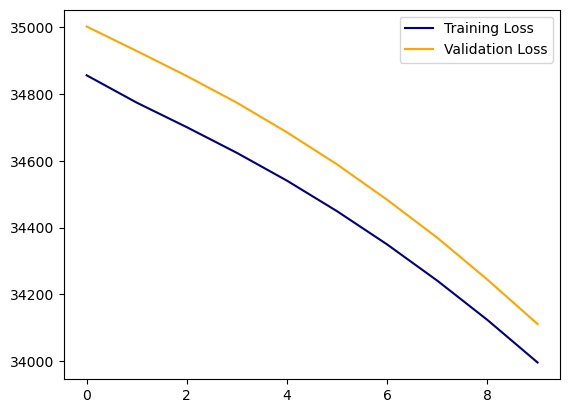

In [9]:
# It's still dropping after 10 epochs! What might we do?
# Keep learning! Run for more epochs.
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='orange', label='Validation Loss')
plt.legend();

# A More Interesting Example: Binary Classification with NLP!
---
The IMDB dataset is a set of 50,000 highly polarized movie reviews. We're predicting sentiment, where 0 = negative and 1 = positive sentiment.

In [10]:
(train_data, train_labels), (test_data, test_labels) = \
    imdb.load_data(num_words=10_000)

In [11]:
# This represents the first 10 words of a review.
train_data[0][:10]

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65]

In [12]:
# Is this review positive or negative?
train_labels[0]

1

In [13]:
# How balanced is our data?
train_labels.mean()

0.5

In [14]:
# Map our 1s and 0s to be floats.
y_train = np.array(train_labels).astype('float')
y_test = np.array(test_labels).astype('float')

# Loss functions, etc. will expect floating-point decimals for y.
# This can also avoid errors when comparing our true and predicted values,
# since our predicted values will usually come in the form of floats.
# While this is generally done "under the hood," hard-coding this is never a bad idea.

In [15]:
# Match our numeric indices with the "real" words.
# You should read this later and convince yourself this makes sense.

# Dictionary of words and their indices.
word_ix = imdb.get_word_index()
key_to_word = {v: k for k, v in word_ix.items()}

# Decode our training and testing data.
train_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in train_data
]
test_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in test_data
]

In [16]:
train_decoded[0]

" this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert  is an amazing actor and now the same being director  father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for  and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also  to the two little boy's that played the  of norman and paul they were just brilliant children are often left out of the  list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you think the

In [17]:
# Count vectorize my data! (All default variables are ok)
cv = CountVectorizer()
X_train = cv.fit_transform(train_decoded).toarray()
X_test = cv.transform(test_decoded).toarray()

In [18]:
type(X_train)

numpy.ndarray

In [19]:
# Build me a neural net with the following specs:
# - Two hidden layers each with 16 nodes and relu activation
# - One output layer... but what activation do we use here?
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(16, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [20]:
# Model summary - what's it look like?
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │       156,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 156,641 (611.88 KB)

 Trainable params: 156,641 (611.88 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Compile the model 
model.compile(
    optimizer='rmsprop',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [22]:
history = model.fit(
    X_train, train_labels,
    epochs=20,
    batch_size=512,
    validation_data=(X_test, test_labels),
    verbose=2
)

Epoch 1/20
49/49 - 6s - 125ms/step - accuracy: 0.7913 - loss: 0.5052 - val_accuracy: 0.8609 - val_loss: 0.3948
Epoch 2/20
49/49 - 3s - 56ms/step - accuracy: 0.8946 - loss: 0.3163 - val_accuracy: 0.8794 - val_loss: 0.3217
Epoch 3/20
49/49 - 2s - 40ms/step - accuracy: 0.9134 - loss: 0.2485 - val_accuracy: 0.8872 - val_loss: 0.2929
Epoch 4/20
49/49 - 2s - 39ms/step - accuracy: 0.9251 - loss: 0.2155 - val_accuracy: 0.8871 - val_loss: 0.2887
Epoch 5/20
49/49 - 2s - 40ms/step - accuracy: 0.9339 - loss: 0.1880 - val_accuracy: 0.8828 - val_loss: 0.2994
Epoch 6/20
49/49 - 2s - 39ms/step - accuracy: 0.9399 - loss: 0.1690 - val_accuracy: 0.8834 - val_loss: 0.3026
Epoch 7/20
49/49 - 2s - 39ms/step - accuracy: 0.9464 - loss: 0.1512 - val_accuracy: 0.8780 - val_loss: 0.3251
Epoch 8/20
49/49 - 2s - 41ms/step - accuracy: 0.9518 - loss: 0.1386 - val_accuracy: 0.8772 - val_loss: 0.3321
Epoch 9/20
49/49 - 2s - 40ms/step - accuracy: 0.9566 - loss: 0.1245 - val_accuracy: 0.8714 - val_loss: 0.3621
Epoch 10/

In [23]:
model.evaluate(X_test, test_labels)

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8616 - loss: 0.5613


[0.5602009892463684, 0.8613200187683105]

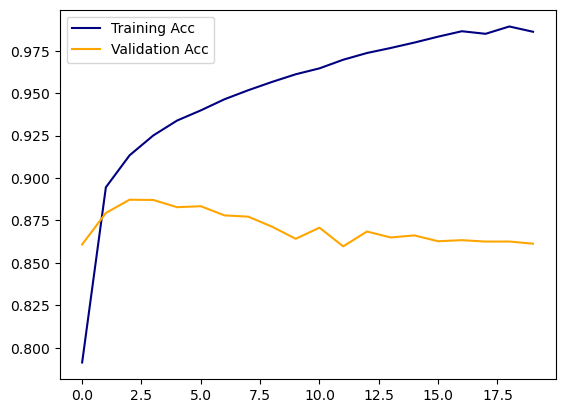

In [24]:
plt.plot(history.history['accuracy'], c='navy', label='Training Acc')
plt.plot(history.history['val_accuracy'], c='orange', label='Validation Acc')
plt.legend();

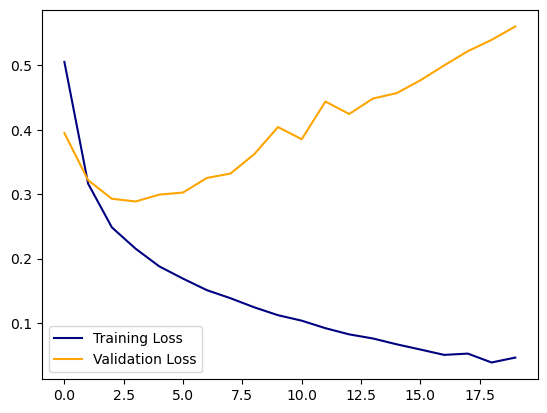

In [25]:
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='orange', label='Validation Loss')
plt.legend();

# If Time: Another one!
Let's try another, much bigger problem! This time we have Reuters news articles and 46 mutually exclusive topic labels.

In [26]:
(train_data, train_labels), (test_data, test_labels) = \
    reuters.load_data(num_words=10_000)

In [27]:
# Again, for the sake of time...
# Decode data - I'll do this quickly now, but you should read this
# later and convince yourself this makes sense.
word_ix = reuters.get_word_index()
key_to_word = {v: k for k, v in word_ix.items()}
train_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in train_data
]
test_decoded = [
    ' '.join([key_to_word.get(token - 3, '') for token in review])
    for review in test_data
]

cv = CountVectorizer()
X_train = cv.fit_transform(train_decoded).toarray()
X_test = cv.transform(test_decoded).toarray()

In [28]:
# Fit me a new model with:
# - Two dense layers with 64 nodes in each (and what activation?)
# - One output layer... with how many output nodes? And what activation?
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(46, activation='softmax'))

In [29]:
# Summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │       618,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 46)             │         2,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 625,966 (2.39 MB)

 Trainable params: 625,966 (2.39 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.compile(
    optimizer='rmsprop',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
history = model.fit(
    X_train, train_labels,
    epochs=20,
    batch_size=512,
    validation_data=(X_test, test_labels),
    verbose=2
)

Epoch 1/20
18/18 - 2s - 91ms/step - accuracy: 0.5556 - loss: 2.6831 - val_accuracy: 0.6825 - val_loss: 1.8329
Epoch 2/20
18/18 - 1s - 34ms/step - accuracy: 0.7395 - loss: 1.4684 - val_accuracy: 0.7284 - val_loss: 1.4038
Epoch 3/20
18/18 - 1s - 34ms/step - accuracy: 0.7912 - loss: 1.0747 - val_accuracy: 0.7596 - val_loss: 1.2061
Epoch 4/20
18/18 - 1s - 35ms/step - accuracy: 0.8316 - loss: 0.8446 - val_accuracy: 0.7640 - val_loss: 1.1780
Epoch 5/20
18/18 - 1s - 35ms/step - accuracy: 0.8640 - loss: 0.6904 - val_accuracy: 0.7854 - val_loss: 1.0512
Epoch 6/20
18/18 - 1s - 35ms/step - accuracy: 0.8868 - loss: 0.5681 - val_accuracy: 0.8001 - val_loss: 1.0105
Epoch 7/20
18/18 - 1s - 35ms/step - accuracy: 0.9047 - loss: 0.4762 - val_accuracy: 0.7961 - val_loss: 0.9817
Epoch 8/20
18/18 - 1s - 35ms/step - accuracy: 0.9176 - loss: 0.4113 - val_accuracy: 0.8010 - val_loss: 0.9933
Epoch 9/20
18/18 - 1s - 34ms/step - accuracy: 0.9262 - loss: 0.3508 - val_accuracy: 0.8010 - val_loss: 1.0235
Epoch 10/2

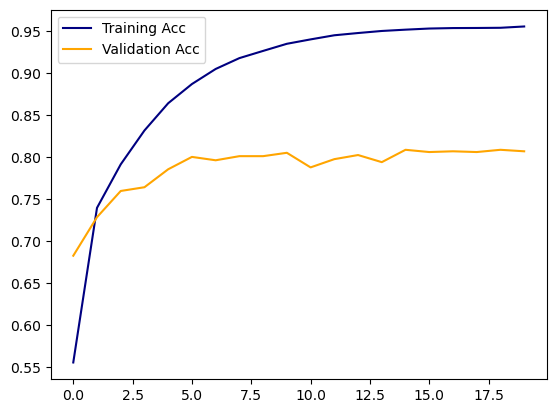

In [32]:
plt.plot(history.history['accuracy'], c='navy', label='Training Acc')
plt.plot(history.history['val_accuracy'], c='orange', label='Validation Acc')
plt.legend();

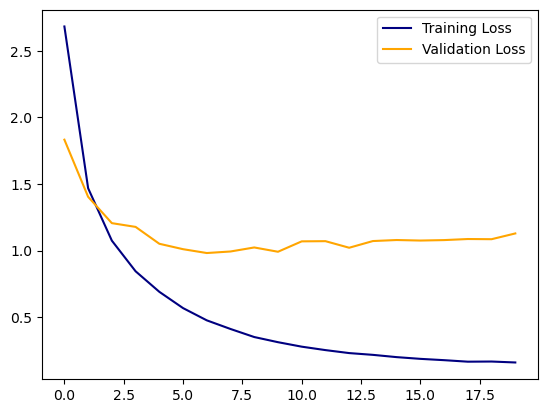

In [33]:
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='orange', label='Validation Loss')
plt.legend();